# NISAR backscatter time series at the 2026 field plots

HHHH (co-pol), HVHV (cross-pol) and their ratio, sampled in a 3x3 window at
each of the 7 Runkle gauges, for all 38 granules covering them.

**Ascending and descending are kept apart.** Backscatter differs systematically
with viewing geometry, so pooling the two injects variance that looks like
signal. Tracks 12 and 84 are both descending but are still different
geometries -- `GROUP_BY` lets you split by track instead if you want to see
that.

Edit **Config**, re-run it and the plot cell you care about. Loading is cheap
here, so iteration is fast.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 15,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.title_fontsize': 14, 'figure.titlesize': 20,
})
print("ready")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


ready


## 2. Config

In [2]:
# Resolve whether the notebook is run from notebooks/ (Jupyter's default) or
# from the repo root.
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent)
            if (p / "outputs" / "nisar_at_gauges.csv").exists())
CSV = ROOT / "outputs" / "nisar_at_gauges.csv"

# Which statistic to plot: "mean" averages the 3x3 in linear power (default),
# "median" is more robust to a single bright scatterer in the window.
STAT = "mean"            # "mean" | "median"

# How to separate viewing geometries into columns.
GROUP_BY = "direction"   # "direction" (ASC/DESC) | "track" (12/84/105)

# One colour per gauge. The four Way fields are ~700 m apart and share a
# colour family so the two clusters are easy to tell apart.
GAUGE_COLOR = {
    "W3-EC": "#1f77b4", "W3-CS": "#4f9fd4", "W4-EC": "#17becf", "W4-CS": "#6fd4de",
    "S16":   "#d62728", "R8":    "#ff7f0e", "S0":    "#2ca02c",
}
# --- smoothing -------------------------------------------------------------
# Each TRACK repeats every 12 days. Descending looks like 6-day sampling only
# because tracks 12 and 84 interleave -- but those are different viewing
# geometries, so smoothing across them blends look angles. Default is to smooth
# within track.
SMOOTH = True
SMOOTH_BY = ["gauge_id", "track"]   # or ["gauge_id", "direction"] to pool tracks
SMOOTH_WINDOW = "25D"               # time-based; "25D" spans ~2-3 passes.
                                    # An integer instead = that many passes.
SMOOTH_CENTER = True                # centred: this is analysis, not forecasting

MARKER = "o"
LINEWIDTH = 1.8
MARKERSIZE = 6
FIGSIZE = (20, 13)
SAVE_TO = ROOT / "outputs" / "nisar_timeseries.png"
DPI = 120

## 3. Load

In [3]:
d = pd.read_csv(CSV)
d["date"] = pd.to_datetime(d.acq_datetime_utc).dt.tz_localize(None)

HH, HV = f"hhhh_db_{STAT}", f"hvhv_db_{STAT}"
# ratio_db is computed from the linear MEANS in the extractor. For the median
# variant, recompute here from the linear medians -- a difference of dB values
# is a ratio, but it must come from the matching statistic.
d["ratio"] = (d.ratio_db if STAT == "mean"
              else 10*np.log10(d.hhhh_lin_median / d.hvhv_lin_median))

SERIES = [(HH, "co-pol HHHH", "dB (gamma0)"),
          (HV, "cross-pol HVHV", "dB (gamma0)"),
          ("ratio", "ratio HH - HV", "dB")]

print(f"{len(d)} rows | {d.granule.nunique()} granules | {d.gauge_id.nunique()} gauges")
print(f"{d.date.min().date()} -> {d.date.max().date()}")
print(d.groupby(["track", "direction"]).size().to_string())

266 rows | 38 granules | 7 gauges
2026-04-04 -> 2026-10-07
track  direction
12     DESC         105
84     DESC          98
105    ASC           63


## 3b. Smoothing

Rolling mean **in linear power**, within track.

In [4]:

def smooth(data, cols, by=SMOOTH_BY, window=SMOOTH_WINDOW, center=SMOOTH_CENTER):
    """Rolling mean of backscatter, computed in LINEAR POWER.

    Averaging dB values gives the geometric mean of the powers, which is not
    the mean backscatter -- the same reason the 3x3 window is averaged in
    linear. So: dB -> linear -> rolling mean -> dB.

    A time-based window ("25D") is used rather than a fixed number of rows,
    because passes are not evenly spaced once a track misses a cycle (gaps run
    12 to 24 days). min_periods=1 means the ends are smoothed over fewer
    points rather than dropped -- they are correspondingly noisier.

    Returns a copy with <col>_sm added.
    """
    out = []
    for _, g in data.groupby(by, dropna=False):
        g = g.sort_values("date").copy()
        r = g.set_index("date")
        for col in cols:
            lin = 10 ** (r[col] / 10)
            if isinstance(window, str):
                sm = lin.rolling(window, center=center, min_periods=1).mean()
            else:
                sm = lin.rolling(window, center=center, min_periods=1).mean()
            g[f"{col}_sm"] = (10 * np.log10(sm)).values
        out.append(g)
    return pd.concat(out).sort_index()


SM_COLS = [HH, HV, "ratio"]
if SMOOTH:
    d = smooth(d, SM_COLS)
    n_per = d.groupby(SMOOTH_BY).size()
    print(f"smoothed {SM_COLS} over {SMOOTH_WINDOW}, grouped by {SMOOTH_BY}")
    print(f"  {len(n_per)} groups, {n_per.min()}-{n_per.max()} passes each")
    chg = (d[f"{HH}_sm"] - d[HH]).abs()
    print(f"  |smoothed - raw| for HHHH: median {chg.median():.2f} dB, "
          f"max {chg.max():.2f} dB")


smoothed ['hhhh_db_mean', 'hvhv_db_mean', 'ratio'] over 25D, grouped by ['gauge_id', 'track']
  21 groups, 9-15 passes each
  |smoothed - raw| for HHHH: median 0.72 dB, max 5.25 dB


## 4. The plot

Rows are the three quantities, columns are the viewing geometries. Each line is
one gauge.

saved /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/nisar_timeseries.png


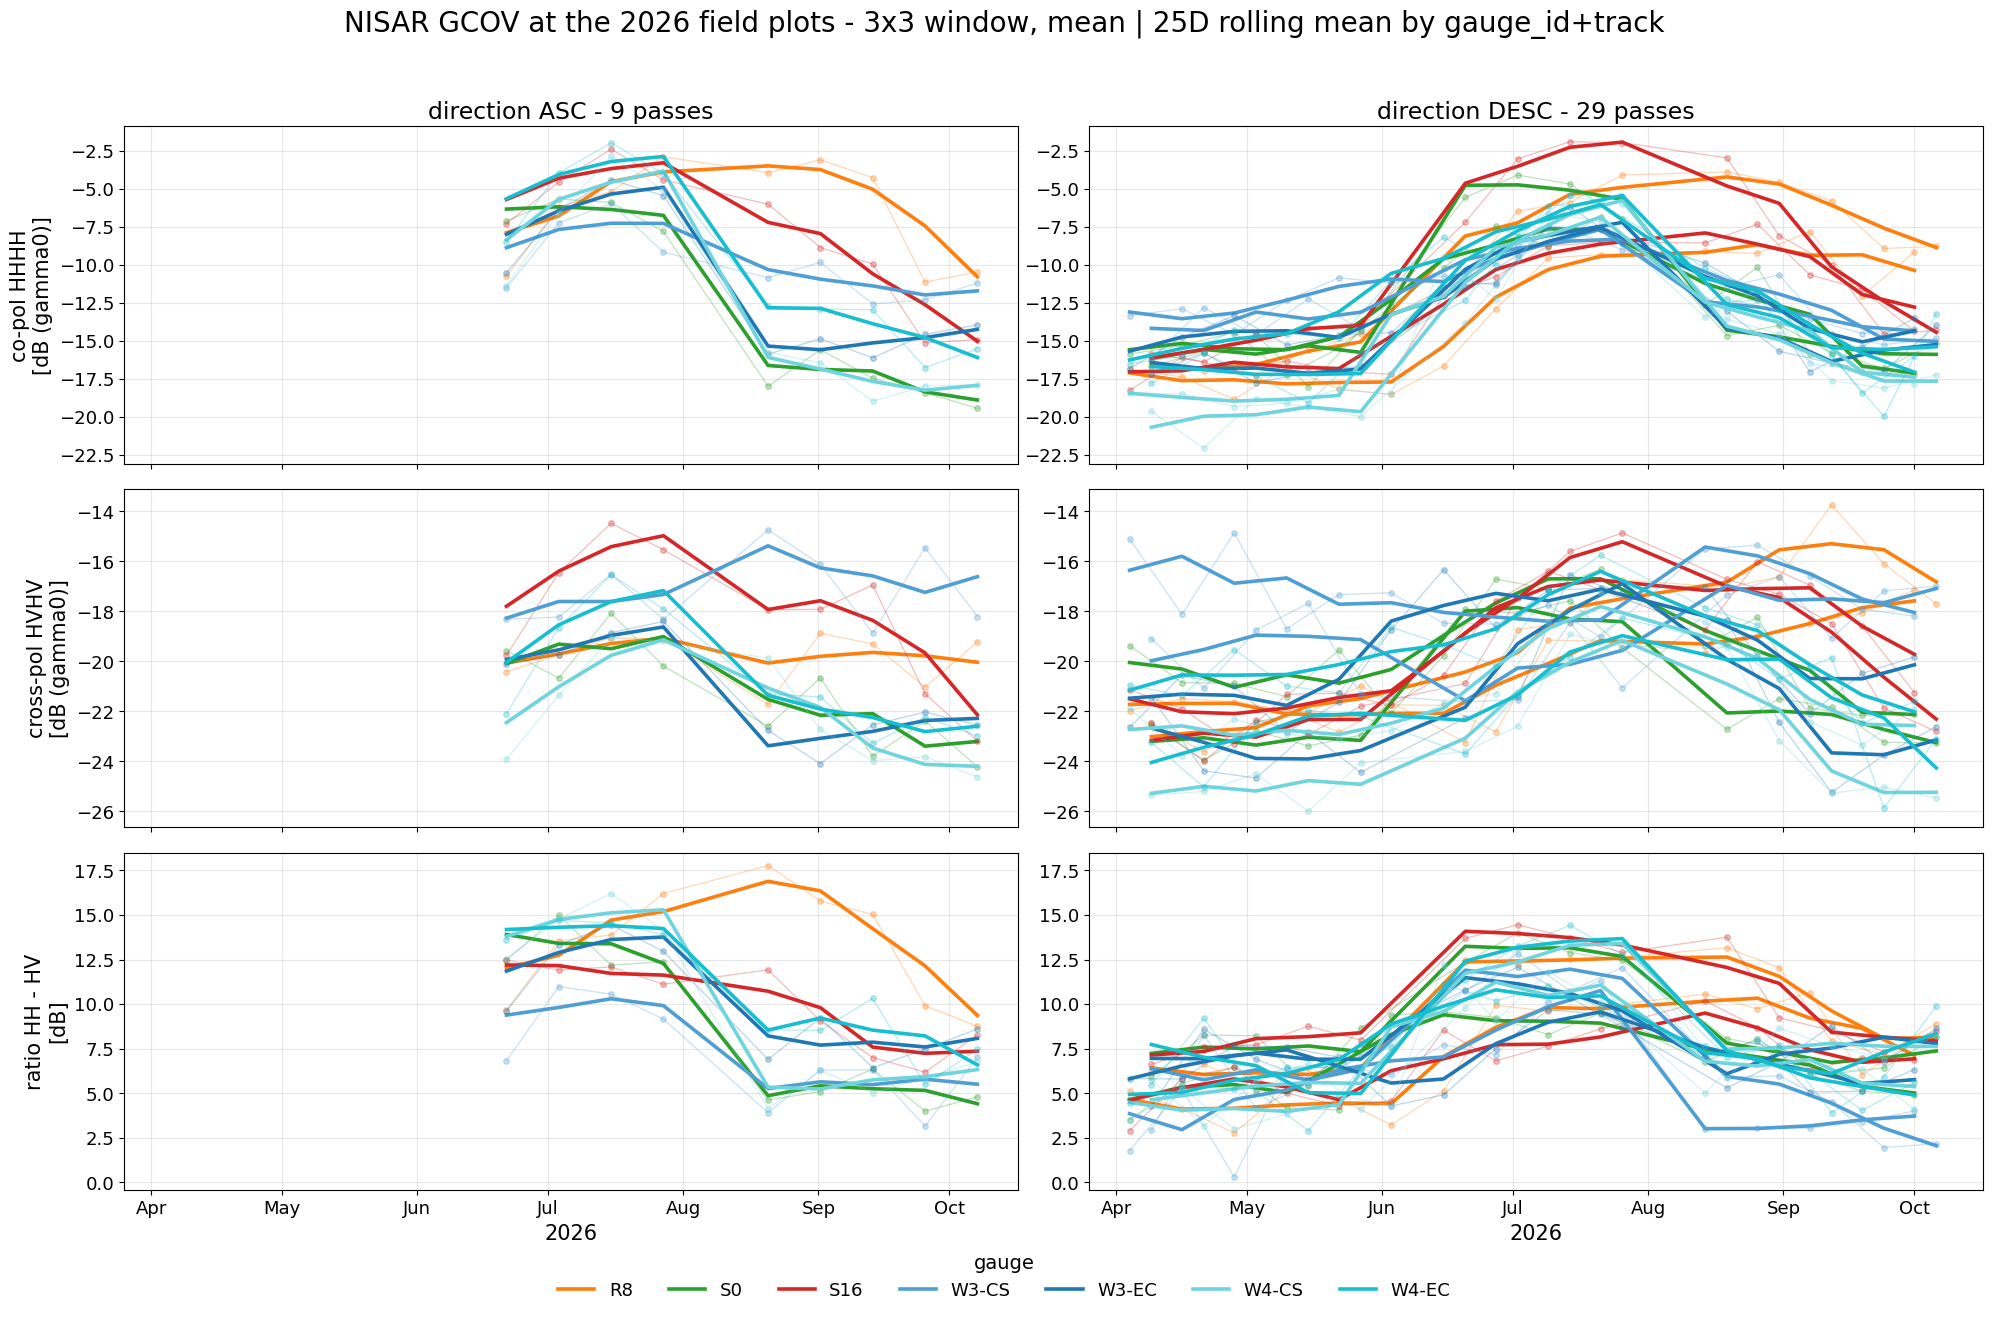

In [5]:
def timeseries(data, group_by=GROUP_BY, save=None):
    groups = sorted(data[group_by].unique(), key=str)
    fig, axes = plt.subplots(len(SERIES), len(groups), figsize=FIGSIZE,
                             sharex=True, squeeze=False)

    for j, grp in enumerate(groups):
        sub = data[data[group_by] == grp]
        for i, (col, label, unit) in enumerate(SERIES):
            ax = axes[i][j]
            # Draw one line per SMOOTHING group, not per gauge: a smoothed
            # series computed within track must not be connected across
            # tracks, or the line sawtooths between two separate estimates.
            keys = SMOOTH_BY if (SMOOTH and f"{col}_sm" in sub) else ["gauge_id"]
            seen = set()
            for kv, g in sub.groupby(keys, dropna=False):
                kv = kv if isinstance(kv, tuple) else (kv,)
                gid = kv[keys.index("gauge_id")]
                g = g.sort_values("date")
                c_ = GAUGE_COLOR.get(gid, "#888")
                smcol = f"{col}_sm"
                lab = gid if gid not in seen else None
                seen.add(gid)
                if SMOOTH and smcol in g:
                    ax.plot(g.date, g[col], marker=MARKER, ms=MARKERSIZE-2,
                            lw=0.9, color=c_, alpha=0.30)
                    ax.plot(g.date, g[smcol], lw=LINEWIDTH+0.8, color=c_,
                            label=lab)
                else:
                    ax.plot(g.date, g[col], marker=MARKER, ms=MARKERSIZE,
                            lw=LINEWIDTH, color=c_, label=lab)
            ax.grid(alpha=0.3)
            if j == 0:
                ax.set_ylabel(f"{label}\n[{unit}]")
            if i == 0:
                n = sub.granule.nunique()
                extra = ("" if group_by == "direction"
                         else f"  ({sub.direction.iloc[0]})")
                ax.set_title(f"{group_by} {grp}{extra} - {n} passes")
            if i == len(SERIES) - 1:
                ax.xaxis.set_major_locator(mdates.MonthLocator())
                ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
                ax.set_xlabel("2026")

    # Shared y-limits per row so panels are comparable across columns.
    for i in range(len(SERIES)):
        lo = min(a.get_ylim()[0] for a in axes[i])
        hi = max(a.get_ylim()[1] for a in axes[i])
        for a in axes[i]:
            a.set_ylim(lo, hi)

    h, l = axes[0][0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=len(l), frameon=False,
               bbox_to_anchor=(0.5, -0.01), title="gauge")
    sm_note = (f" | {SMOOTH_WINDOW} rolling mean by {'+'.join(SMOOTH_BY)}"
           if SMOOTH else "")
    fig.suptitle(f"NISAR GCOV at the 2026 field plots - 3x3 window, "
                 f"{STAT}{sm_note}", y=0.995)
    fig.tight_layout(rect=[0, 0.03, 1, 0.98])
    if save:
        fig.savefig(save, dpi=DPI, bbox_inches="tight")
        print("saved", save)
    return fig


timeseries(d, save=SAVE_TO)
plt.show()

## 5. Per-gauge view

The same data faceted by site, with all three quantities on one axis. Easier
for reading an individual field's season; harder for comparing fields.

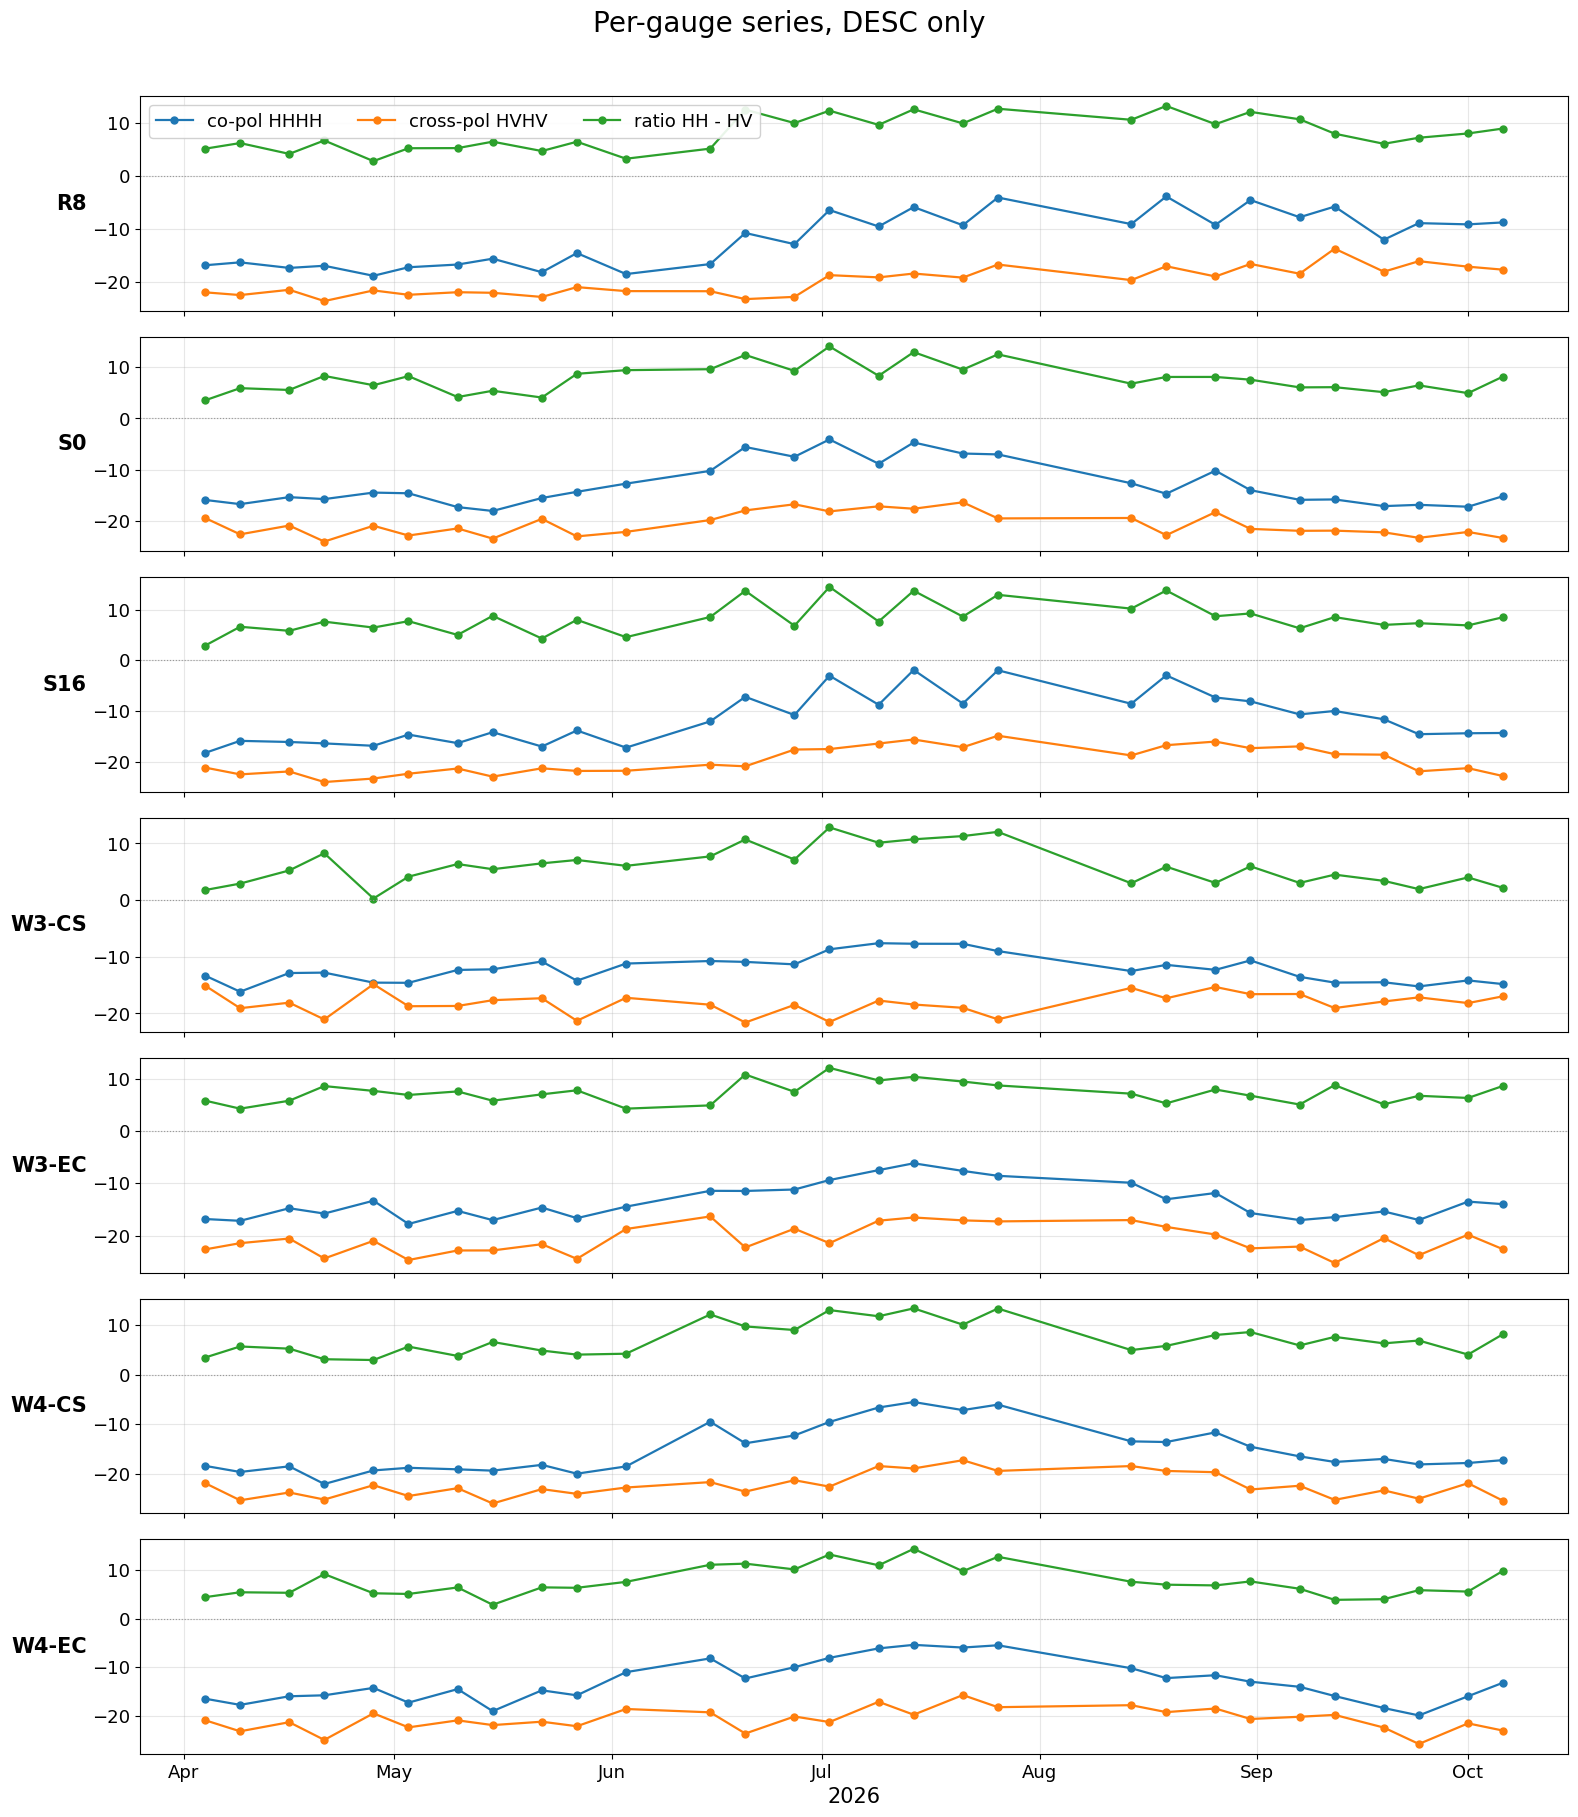

In [6]:
def per_gauge(data, direction="DESC"):
    sub = data[data.direction == direction]
    gauges = sorted(sub.gauge_id.unique())
    fig, axes = plt.subplots(len(gauges), 1, figsize=(16, 2.6*len(gauges)),
                             sharex=True)
    for ax, gid in zip(np.atleast_1d(axes), gauges):
        g = sub[sub.gauge_id == gid].sort_values("date")
        for col, label, _ in SERIES:
            ax.plot(g.date, g[col], marker="o", ms=5, lw=1.6, label=label)
        ax.set_ylabel(gid, rotation=0, ha="right", va="center", fontweight="bold")
        ax.grid(alpha=0.3)
        ax.axhline(0, color="#999", lw=0.8, ls=":")
    np.atleast_1d(axes)[0].legend(ncol=3, loc="upper left", framealpha=0.9)
    np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.MonthLocator())
    np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    np.atleast_1d(axes)[-1].set_xlabel("2026")
    fig.suptitle(f"Per-gauge series, {direction} only", y=0.999)
    fig.tight_layout(rect=[0, 0, 1, 0.99])
    return fig


per_gauge(d, direction="DESC")
plt.show()

## 6. Numbers behind the plot

In [7]:
summary = (d.groupby(["gauge_id", "direction"])
             .agg(n=("granule", "nunique"),
                  hh_min=(HH, "min"), hh_med=(HH, "median"), hh_max=(HH, "max"),
                  hv_med=(HV, "median"),
                  ratio_min=("ratio", "min"), ratio_med=("ratio", "median"),
                  ratio_max=("ratio", "max"))
             .round(2).reset_index())
summary

,gauge_id,direction,n,hh_min,hh_med,hh_max,hv_med,ratio_min,ratio_med,ratio_max
0,R8,ASC,9,-11.13,-5.18,-2.90,-19.30,8.75,13.87,17.78
1,R8,DESC,29,-18.85,-10.78,-3.89,-19.66,2.76,7.93,13.16
2,S0,ASC,9,-19.43,-15.58,-5.67,-20.67,3.98,6.34,14.99
3,S0,DESC,29,-18.01,-14.57,-4.10,-21.41,3.51,8.06,13.99
4,S16,ASC,9,-15.12,-7.30,-2.40,-17.92,6.17,11.11,12.47
5,S16,DESC,29,-18.24,-12.03,-1.90,-20.88,2.89,7.71,14.45
6,W3-CS,ASC,9,-12.57,-10.85,-5.96,-18.21,3.15,6.82,10.98
7,W3-CS,DESC,29,-16.18,-12.34,-7.61,-18.12,0.28,5.90,12.83
8,W3-EC,ASC,9,-16.11,-13.95,-4.41,-22.03,6.42,9.22,14.44
9,W3-EC,DESC,29,-17.77,-14.46,-6.17,-21.44,4.27,7.14,12.07


## Caveats carried from the extraction

- **3x3 window at 10 m posting.** Re-run `extract_at_gauges.py` with
  `--window 1` and `--window 5` and compare: the spread between them is the
  speckle contribution, and it is not small at L-band.
- **The four Way fields span ~0.7 km**, i.e. roughly 70 pixels apart. Their
  windows do not overlap, but they share weather, management and much of the
  surrounding landscape, so treat them as correlated rather than independent.
- **No water level here yet.** Pairing with the 30-minute logger record is the
  next step, and that needs the TOA5 `TIMESTAMP` timezone settled first --
  the acquisitions are ~01:00 and ~11:20 UTC, so a 5-6 hour error silently
  mispairs every point during flood-up and drawdown.